In [ ]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

In [ ]:
# 1. Montar o Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Defina o caminho onde estão seus arquivos no Drive
DATA_DIR = '/content/drive/MyDrive/plant-pathology-2020-fgvc7'

train_df = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
print("Total de imagens de treino:", len(train_df))
display(train_df.head())

Mounted at /content/drive
Total de imagens de treino: 1821


,image_id,healthy,multiple_diseases,rust,scab
0,Train_0,0,0,0,1
1,Train_1,0,1,0,0
2,Train_2,1,0,0,0
3,Train_3,0,0,1,0
4,Train_4,1,0,0,0


In [ ]:
# Mover as colunas de labels para um array numpy de classes mutuamente exclusivas
label_columns = ['healthy', 'multiple_diseases', 'rust', 'scab']

# Vamos identificar as colunas de rótulo dinamicamente exceto image_id
target_cols = [col for col in train_df.columns if col != 'image_id']
print("Colunas de classes encontradas:", target_cols)

# Converter one-hot ou colunas binárias em um único índice de classe (0, 1, 2, 3)
train_df['label'] = train_df[target_cols].idxmax(axis=1)
class_names = sorted(train_df['label'].unique())
class_to_idx = {name: i for i, name in enumerate(class_names)}
train_df['label_idx'] = train_df['label'].map(class_to_idx)

print("Mapeamento de classes:", class_to_idx)

# Caminho completo das imagens
IMAGES_DIR = os.path.join(DATA_DIR, 'images')
train_df['image_path'] = train_df['image_id'].apply(lambda x: os.path.join(IMAGES_DIR, f"{x}.jpg"))

Colunas de classes encontradas: ['healthy', 'multiple_diseases', 'rust', 'scab']
Mapeamento de classes: {'healthy': 0, 'multiple_diseases': 1, 'rust': 2, 'scab': 3}


In [ ]:
IMG_HEIGHT, IMG_WIDTH = 512, 512
BATCH_SIZE = 16

# carregar e Pré-processar as imagens
def load_and_preprocess_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_HEIGHT, IMG_WIDTH])
    image = image / 255.0  # Mantém normalizado entre [0, 1]
    return image, label

# Separar em Treino e Validação (80/20) estratificado se possível
from sklearn.model_selection import train_test_split
train_paths, val_paths, train_labels_arr, val_labels_arr = train_test_split(
    train_df['image_path'].values,
    train_df['label_idx'].values,
    test_size=0.2,
    random_state=42,
    stratify=train_df['label_idx'].values
)

# Converter labels para categorical (One-Hot Encoding para 4 classes)
NUM_CLASSES = len(class_names)
train_labels_oh = tf.keras.utils.to_categorical(train_labels_arr, num_classes=NUM_CLASSES)
val_labels_oh = tf.keras.utils.to_categorical(val_labels_arr, num_classes=NUM_CLASSES)

# Criar datasets tf.data
train_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels_oh))
train_dataset = train_dataset.map(load_and_preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
train_dataset = train_dataset.shuffle(buffer_size=1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_dataset = tf.data.Dataset.from_tensor_slices((val_paths, val_labels_oh))
val_dataset = val_dataset.map(load_and_preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
val_dataset = val_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [ ]:
# Cálculo dos Pesos de Classes (Para o Desbalanceamento)
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels_arr),
    y=train_labels_arr
)
class_weights_dict = dict(enumerate(class_weights))
print("Pesos calculados para cada classe:", class_weights_dict)

Pesos calculados para cada classe: {0: np.float64(0.8813559322033898), 1: np.float64(4.986301369863014), 2: np.float64(0.7323943661971831), 3: np.float64(0.7695560253699789)}


In [ ]:
# 1. Camada de Data Augmentation para combater Overfitting
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.05),
], name="data_augmentation")

def res_block(x, filters, kernel_size=(3, 3), stride=1, conv_shortcut=True, name=None):
    shortcut = x
    x = layers.Conv2D(filters, kernel_size, strides=stride, padding="same", name=f"{name}_conv1")(x)
    x = layers.BatchNormalization(name=f"{name}_bn1")(x)
    x = layers.ReLU(name=f"{name}_relu1")(x)

    x = layers.Conv2D(filters, kernel_size, padding="same", name=f"{name}_conv2")(x)
    x = layers.BatchNormalization(name=f"{name}_bn2")(x)

    if conv_shortcut:
        shortcut = layers.Conv2D(filters, 1, strides=stride, name=f"{name}_shortcut_conv")(shortcut)
        shortcut = layers.BatchNormalization(name=f"{name}_shortcut_bn")(shortcut)

    x = layers.add([x, shortcut], name=f"{name}_add")
    x = layers.ReLU(name=f"{name}_out_relu")(x)
    return x

def build_resnet18_clean(input_shape=(512, 512, 3), num_classes=4):
    inputs = layers.Input(shape=input_shape)

    # Aplica Data Augmentation leve apenas no treino
    x = data_augmentation(inputs)

    x = layers.Conv2D(64, (7, 7), strides=2, padding="same", name="conv1")(x)
    x = layers.BatchNormalization(name="bn1")(x)
    x = layers.ReLU(name="relu1")(x)
    x = layers.MaxPooling2D(pool_size=(3, 3), strides=2, padding="same", name="max_pool")(x)

    # Blocos ResNet originais
    x = res_block(x, 64, name="block1_1", conv_shortcut=False)
    x = res_block(x, 64, name="block1_2", conv_shortcut=False)

    x = res_block(x, 128, stride=2, name="block2_1")
    x = res_block(x, 128, name="block2_2", conv_shortcut=False)

    x = res_block(x, 256, stride=2, name="block3_1")
    x = res_block(x, 256, name="block3_2", conv_shortcut=False)

    x = res_block(x, 512, stride=2, name="block4_1")
    x = res_block(x, 512, name="block4_2", conv_shortcut=False)

    x = layers.GlobalAveragePooling2D(name="avg_pool")(x)

    # Sem Dropout agressivo para permitir que a rede aprenda bem
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)

    model = models.Model(inputs, outputs, name="resnet18_clean_plant")
    return model

model = build_resnet18_clean(input_shape=(512, 512, 3), num_classes=NUM_CLASSES)
model.summary()

Model: "resnet18_clean_plant"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 512, 512,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 512, 512,  │          0 │ input_layer[0][0] │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1 (Conv2D)      │ (None, 256, 256,  │      9,472 │ data_augmentatio… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn1                 │ (None, 256, 256,  │        256 │ conv1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ relu1 (ReLU)        │ (None, 256, 256,  │          0 │ bn1[0][0]         │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pool            │ (None, 128, 128,  │          0 │ relu1[0][0]       │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_1_conv1      │ (None, 128, 128,  │     36,928 │ max_pool[0][0]    │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_1_bn1        │ (None, 128, 128,  │        256 │ block1_1_conv1[0… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_1_relu1      │ (None, 128, 128,  │          0 │ block1_1_bn1[0][… │
│ (ReLU)              │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_1_conv2      │ (None, 128, 128,  │     36,928 │ block1_1_relu1[0… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_1_bn2        │ (None, 128, 128,  │        256 │ block1_1_conv2[0… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_1_add (Add)  │ (None, 128, 128,  │          0 │ block1_1_bn2[0][… │
│                     │ 64)               │            │ max_pool[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_1_out_relu   │ (None, 128, 128,  │          0 │ block1_1_add[0][… │
│ (ReLU)              │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_2_conv1      │ (None, 128, 128,  │     36,928 │ block1_1_out_rel… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_2_bn1        │ (None, 128, 128,  │        256 │ block1_2_conv1[0… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_2_relu1      │ (None, 128, 128,  │          0 │ block1_2_bn1[0][… │
│ (ReLU)              │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_2_conv2      │ (None, 128, 128,  │     36,928 │ block1_2_relu1[0

 Total params: 11,192,964 (42.70 MB)

 Trainable params: 11,183,364 (42.66 MB)

 Non-trainable params: 9,600 (37.50 KB)

In [ ]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath='/content/drive/MyDrive/best_resnet18_clean.weights.h5',
        save_weights_only=True,
        monitor='val_auc',
        mode='max',
        save_best_only=True
    )
]

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001), # Taxa padrão ideal para treinar do zero
    loss='categorical_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

# Treinamento
history = model.fit(
    train_dataset,
    epochs=30,
    validation_data=val_dataset,
    class_weight=class_weights_dict,
    callbacks=callbacks
)

Epoch 1/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 771s 4s/step - accuracy: 0.3173 - auc: 0.5880 - loss: 1.5701 - val_accuracy: 0.3178 - val_auc: 0.5195 - val_loss: 1.4015
Epoch 2/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 63s 576ms/step - accuracy: 0.4718 - auc: 0.7365 - loss: 1.2301 - val_accuracy: 0.2904 - val_auc: 0.5730 - val_loss: 1.3691
Epoch 3/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 59s 498ms/step - accuracy: 0.5598 - auc: 0.8087 - loss: 1.1343 - val_accuracy: 0.2822 - val_auc: 0.4929 - val_loss: 1.7583
Epoch 4/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 55s 485ms/step - accuracy: 0.6202 - auc: 0.8623 - loss: 0.9934 - val_accuracy: 0.2493 - val_auc: 0.4509 - val_loss: 1.7656
Epoch 5/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 58s 521ms/step - accuracy: 0.6909 - auc: 0.9046 - loss: 0.8429 - val_accuracy: 0.3151 - val_auc: 0.6556 - val_loss: 1.3574
Epoch 6/30
91/91 ━━━━━━━━━━━━━━━━━━━━ 63s 537ms/step - accuracy: 0.6848 - auc: 0.9044 - loss: 0.8188 - val_accuracy: 0.4548 - val_auc: 0.7586 - val_loss: 1.1892
Epoch 7/30
91/91 ━━━━━━━━━━━━━━━━━━━

In [ ]:
# Carrega os melhores pesos salvos pelo ModelCheckpoint no Google Drive
model.load_weights('/content/drive/MyDrive/best_resnet18_clean.weights.h5')
print("Melhores pesos carregados com sucesso para a avaliação!")

Melhores pesos carregados com sucesso para a avaliação!


In [ ]:
# Salva o modelo inteiro na sua pasta do Google Drive
model_save_path = '/content/drive/MyDrive/plant_pathology_resnet18_complete.keras'
model.save(model_save_path)

print(f"Modelo completo salvo em: {model_save_path}")

Modelo completo salvo em: /content/drive/MyDrive/plant_pathology_resnet18_complete.keras


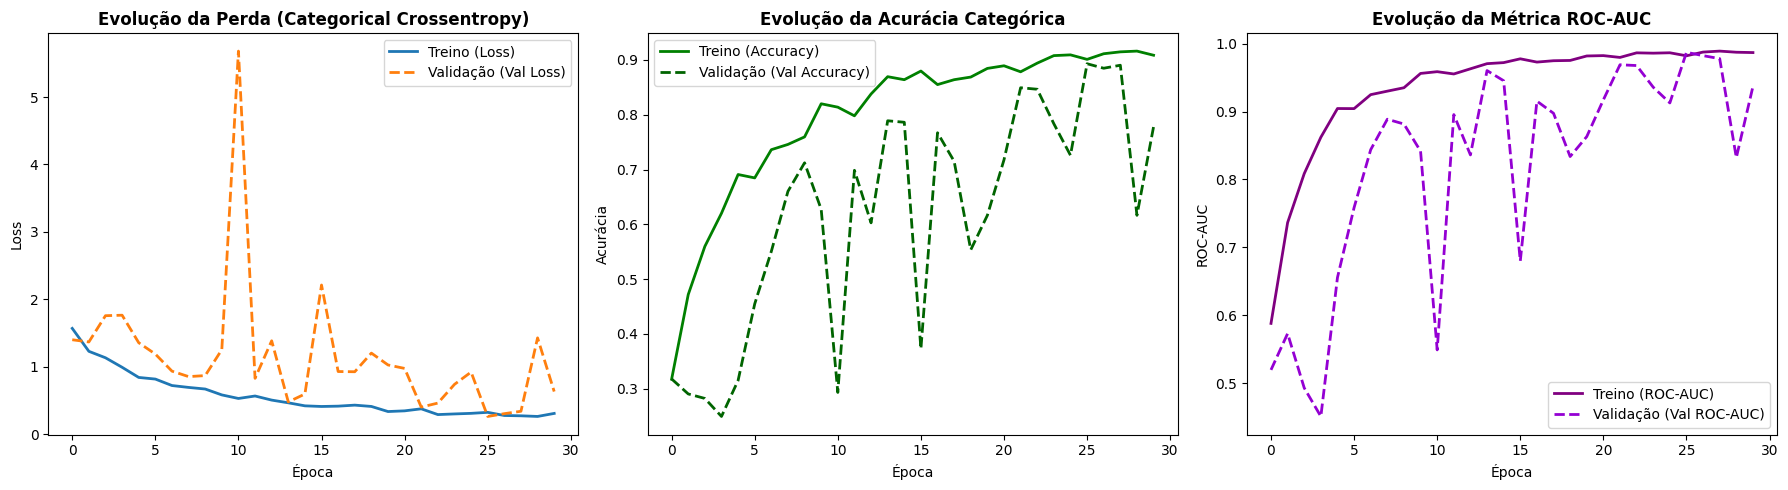

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Certifique-se de que a pasta de gráficos existe
GRAPHS_DIR = '/content/drive/MyDrive/plant_pathology_graphs'
MODELS_DIR = '/content/drive/MyDrive/plant_pathology_models'
os.makedirs(GRAPHS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

# Converter o history em DataFrame
history_df = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Perda (Loss)
axes[0].plot(history_df["loss"], label="Treino (Loss)", lw=2)
axes[0].plot(history_df["val_loss"], label="Validação (Val Loss)", lw=2, linestyle="--")
axes[0].set_title("Evolução da Perda (Categorical Crossentropy)", fontweight="bold")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend()

# 2. Acurácia
axes[1].plot(history_df["accuracy"], label="Treino (Accuracy)", lw=2, color="green")
axes[1].plot(history_df["val_accuracy"], label="Validação (Val Accuracy)", lw=2, color="darkgreen", linestyle="--")
axes[1].set_title("Evolução da Acurácia Categórica", fontweight="bold")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Acurácia")
axes[1].legend()

# 3. ROC-AUC
axes[2].plot(history_df["auc"], label="Treino (ROC-AUC)", lw=2, color="purple")
axes[2].plot(history_df["val_auc"], label="Validação (Val ROC-AUC)", lw=2, color="darkviolet", linestyle="--")
axes[2].set_title("Evolução da Métrica ROC-AUC", fontweight="bold")
axes[2].set_xlabel("Época")
axes[2].set_ylabel("ROC-AUC")
axes[2].legend()

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "pipeline_single_curves.png"), dpi=300, bbox_inches="tight")
plt.show()

,precision,recall,f1-score,support
healthy,0.8435,0.9417,0.8899,103.0000
multiple_diseases,0.4615,0.3333,0.3871,18.0000
rust,0.9672,0.9440,0.9555,125.0000
scab,0.9130,0.8824,0.8974,119.0000
accuracy,0.8932,0.8932,0.8932,0.8932
macro avg,0.7963,0.7754,0.7825,365.0000
weighted avg,0.8897,0.8932,0.8900,365.0000



--- Resumo de Métricas Globais (Validação) ---
Acurácia Global:      89.32%
Macro F1-Score:       78.25%
Mean ROC-AUC (Macro): 96.74%


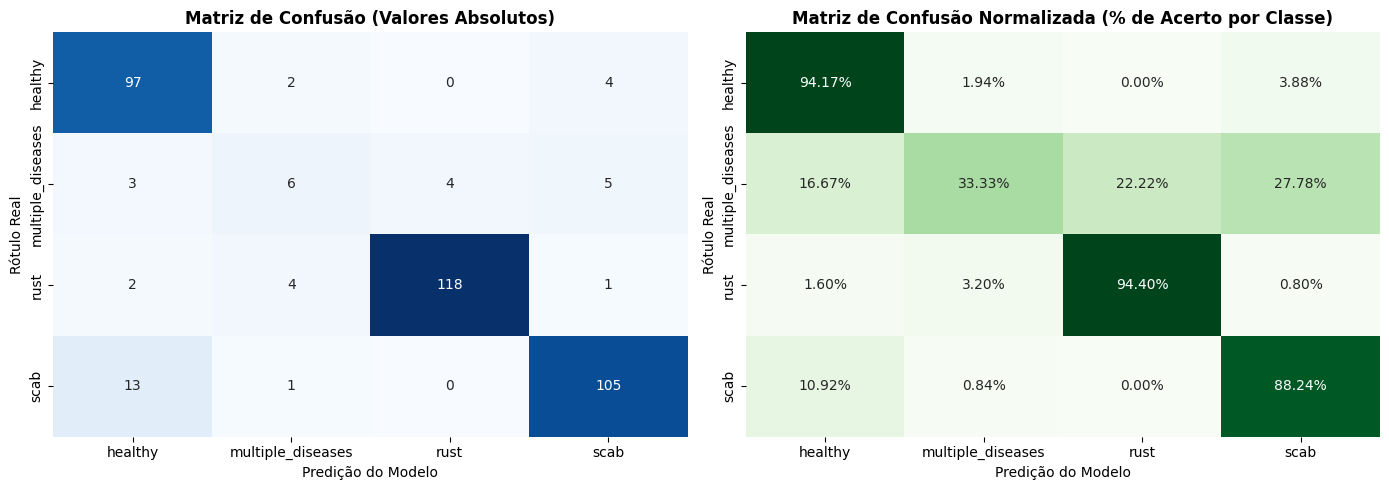

In [ ]:
import seaborn as sns

# Coletar predições e rótulos reais do val_dataset
val_preds_list = []
val_true_list = []

for images, labels in val_dataset:
    preds = model.predict(images, verbose=0)
    val_preds_list.extend(preds)
    val_true_list.extend(labels.numpy())

val_preds_prob = np.array(val_preds_list)
val_true_oh = np.array(val_true_list)

val_preds_idx = val_preds_prob.argmax(axis=1)
val_true_idx = val_true_oh.argmax(axis=1)

# Usando as classes reais encontradas no seu dataframe (ex: ['healthy', 'multiple_diseases', 'rust', 'scab'])
TARGET_COLS = class_names

# Relatório de Classificação
report_dict = classification_report(
    val_true_idx,
    val_preds_idx,
    target_names=TARGET_COLS,
    output_dict=True
)
report_df = pd.DataFrame(report_dict).transpose()
display(report_df.round(4))
report_df.to_csv(os.path.join(MODELS_DIR, "baseline_resnet512_classification_report.csv"))

macro_f1 = report_dict["macro avg"]["f1-score"]
overall_acc = report_dict["accuracy"]
macro_auc = roc_auc_score(val_true_oh, val_preds_prob, average="macro", multi_class="ovr")

print(f"\n--- Resumo de Métricas Globais (Validação) ---")
print(f"Acurácia Global:      {overall_acc * 100:.2f}%")
print(f"Macro F1-Score:       {macro_f1 * 100:.2f}%")
print(f"Mean ROC-AUC (Macro): {macro_auc * 100:.2f}%")

# Matriz de Confusão Dupla (Contagens Brutas vs. Normalizada por Linha)
cm_raw = confusion_matrix(val_true_idx, val_preds_idx)
cm_norm = confusion_matrix(val_true_idx, val_preds_idx, normalize="true")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm_raw, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0], xticklabels=TARGET_COLS, yticklabels=TARGET_COLS)
axes[0].set_title("Matriz de Confusão (Valores Absolutos)", fontweight="bold")
axes[0].set_xlabel("Predição do Modelo")
axes[0].set_ylabel("Rótulo Real")

sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap="Greens", cbar=False, ax=axes[1], xticklabels=TARGET_COLS, yticklabels=TARGET_COLS)
axes[1].set_title("Matriz de Confusão Normalizada (% de Acerto por Classe)", fontweight="bold")
axes[1].set_xlabel("Predição do Modelo")
axes[1].set_ylabel("Rótulo Real")

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "pipeline_single_confusion_matrix.png"), dpi=300, bbox_inches="tight")
plt.show()